## 0. Setup

Starting from the team's final table (85,371 orders), the training period is orders purchased before 1 April 2018 (64,038 orders, split decided by the team, DECISIONS D6).

Section 3 only uses the training data. The test set (orders from April 2018 onward) is not touched here and is evaluated at the end of the project.

The model inputs are the 22 approval-time features. IDs are excluded because they carry no meaning, raw dates are excluded because their information is already in the engineered timing features (plus the delivery date would be a data leakage), and is_late is of course excluded as this is the target variable

In [35]:
import pandas as pd
from pathlib import Path

# Find the project root
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

# Construct the CSV path
csv_path = root / "data" / "processed" / "olist_final.csv"

print("Loading from:", csv_path)
print("File exists:", csv_path.exists())

# Load dataset
df = pd.read_csv(
    csv_path,
    parse_dates=["order_purchase_timestamp"]
)

print("Dataset shape:", df.shape)
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)

# Training period only: orders purchased before 1 April 2018 (the team's split)
train = df[df["order_purchase_timestamp"] < "2018-04-01"]

# Features = everything except IDs, raw dates and the target
non_features = ["order_id", "customer_id", "order_purchase_timestamp", "order_approved_at",
                "order_delivered_customer_date", "order_estimated_delivery_date", "is_late"]
X_train = train.drop(columns=non_features)
y_train = train["is_late"]
print(X_train.shape)

Loading from: c:\Users\wujingyu\OneDrive\Desktop\机器学习\olist-late-delivery-main\data\processed\olist_final.csv
File exists: True
Dataset shape: (85371, 29)
(64038, 22)


## 3.1 Cleaning

### 3.1a Missing Values

Five columns have missing values in the 64,038 training orders (primary product category, max distance, mean distance, max product weight and mean product weight).

Of these 5 columns, the product category column has the most missing values (about 1.83% rows total). The distance columns are both missing about 0.52% of rows, and the product weight columns are missing only about 0.02%.

In [36]:
missing = X_train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"rows_missing": missing,
              "percent": (missing / len(X_train) * 100).round(2)})

,rows_missing,percent
primary_product_category,1169,1.83
mean_distance_km,330,0.52
max_distance_km,330,0.52
mean_product_weight_g,16,0.02
max_product_weight_g,16,0.02


Dropping rows would remove real orders, so we are filling the missing rows instead of removing them. The empty rows in the numerical columns are replaced with the median values, and the empty rows in the category column are replaced with "unknown".

**The below step is shown on a copy of the table. The same filling is applied inside the pipeline (3.4), so it is fit on the training data only.**

Additionally, the distance columns will also get a "was missing" flag in the pipeline (3.4). This is because a missing distance means the ZIP code was not found in the original geolocation table, which might point to strange addresses (and could contribute to why an order was delivered late).

In [37]:
dist_cols = ["mean_distance_km", "max_distance_km"]
weight_cols = ["mean_product_weight_g", "max_product_weight_g"]

X_train_filled = X_train.copy()

for c in dist_cols:
    X_train_filled[c + "_was_missing"] = X_train_filled[c].isna().astype(int)

fill_cols = dist_cols + weight_cols
X_train_filled[fill_cols] = X_train_filled[fill_cols].fillna(X_train_filled[fill_cols].median())
X_train_filled["primary_product_category"] = X_train_filled["primary_product_category"].fillna("unknown")

print(X_train_filled.isna().sum().sum())

0


### 3.1b Outliers

The below table shows which columns have extreme values (potential outliers).

In [38]:
X_train.select_dtypes("number").skew().sort_values(ascending=False).round(1)

total_price                    11.1
seller_count                   10.7
total_freight                   8.7
item_count                      8.2
distinct_product_count          7.7
total_product_volume_cm3        7.7
approval_lag_hours              5.2
freight_to_price_ratio          3.7
mean_product_weight_g           3.6
max_product_weight_g            3.6
mean_distance_km                1.7
max_distance_km                 1.7
promised_days_from_approval     1.3
customer_zip_code_prefix        0.7
same_state_item_share           0.7
approval_month                  0.2
purchase_month                  0.2
purchase_weekday                0.1
purchase_hour                  -0.6
dtype: float64

#### No outliers are removed
We did not remove any outliers because the extreme values are all still real orders (i.e., 0 rows removed). No impossible values were found, so skewed columns are handled with a log transform and scaling instead

In [39]:
cols = ["total_price", "seller_count", "total_freight", "item_count",
        "distinct_product_count", "total_product_volume_cm3", "approval_lag_hours",
        "freight_to_price_ratio", "mean_product_weight_g", "max_product_weight_g"]

summary = X_train[cols].agg(["median", lambda s: s.quantile(0.99), "max"]).T
summary.columns = ["median", "99th percentile", "max"]
summary.round(1)


,median,99th percentile,max
total_price,85.0,978.0,13440.0
seller_count,1.0,2.0,5.0
total_freight,16.7,98.0,1002.3
item_count,1.0,3.0,21.0
distinct_product_count,1.0,2.0,7.0
total_product_volume_cm3,7744.0,140448.0,1476000.0
approval_lag_hours,0.3,87.4,741.4
freight_to_price_ratio,0.2,1.4,5.7
mean_product_weight_g,700.0,19100.0,40425.0
max_product_weight_g,700.0,19400.0,40425.0


### 3.1c Duplicates
There are no duplicate orders (every order_id in the 64,038 training orders appears only once) therefore 0 rows are removed

In [40]:
print(train["order_id"].is_unique)
print(train["order_id"].duplicated().sum())

True
0


## 3.2 Feature Engineering

### 3.2a Feature selection
Two features are dropped from the current features because they do not provide as much useful information: customer_zip_code_prefix and approval_month

customer_zip_code_prefix has 13,584 different values. One-hot encoding them would turn each value into its own column, which would make the table far too big and slow. As well, Customer state and distance columns already describe the locations.

approval_month is the same as purchase_month for 98.2% of orders. As well, the approval timing is already accounted for by the columns approval_lag_hours and promised_days_from_approval.

This leaves 20 features instead of 22.

In [41]:
print(X_train["customer_zip_code_prefix"].nunique())
print((X_train["approval_month"] == X_train["purchase_month"]).mean().round(3))

drop_cols = ["customer_zip_code_prefix", "approval_month"]
X_train_sel = X_train.drop(columns=drop_cols)
print(X_train_sel.shape)

13584
0.982
(64038, 20)


### 3.2b Feature groups

| Group | Features | Why it should help predict late deliveries |
|---|---|---|
| Timing | promised days, approval lag, purchase month, weekday and hour | Short promises, slow approvals and busy periods make delays more likely |
| Location | customer state, seller state | Some regions may be harder to deliver to |
| Distance | mean and max distance, same-state share | The farther a package travels, the longer it takes |
| Order size and cost | item count, seller count, total price, freight, freight-to-price ratio | Larger orders and orders from multiple sellers may be harder to ship on time |
| Product | weight, volume, category | Heavy or bulky products are slower to handle and ship |

### 3.2c Transformations
Discretizing continuous features is not necessary because the models can use the raw numbers. As well, date and time features are already split into month, weekday and hour.

The 13 columns with skew above 1 get a log(1 + x) transform, which makes the distribution more even by compressing the largest values (shrinks the long tails).

We note that log-transforming 3 of these columns did not help much (seller_count, distinct_product_count and item_count). However, keeping them logged is harmless and keeps the treatement consistent.

As well, for the two distance columns, the log transform over-corrects the skew, from +1.7 to −1.1. The skew is still lower than before, so the log transform is kept for these columns.

In [42]:
import numpy as np

log_cols = ["total_price", "seller_count", "total_freight", "item_count",
            "distinct_product_count", "total_product_volume_cm3", "approval_lag_hours",
            "freight_to_price_ratio", "mean_product_weight_g", "max_product_weight_g",
            "mean_distance_km", "max_distance_km", "promised_days_from_approval"]

before = X_train[log_cols].skew()
after = np.log1p(X_train[log_cols]).skew()
pd.DataFrame({"skew before": before, "skew after log": after}).round(1)

,skew before,skew after log
total_price,11.1,0.3
seller_count,10.7,9.8
total_freight,8.7,1.2
item_count,8.2,4.0
distinct_product_count,7.7,6.2
total_product_volume_cm3,7.7,-0.1
approval_lag_hours,5.2,1.0
freight_to_price_ratio,3.7,1.9
mean_product_weight_g,3.6,0.5
max_product_weight_g,3.6,0.4


## 3.3 Scaling and Encoding

### 3.3a Scaling
All numeric columns are standardized (mean 0, standard deviation 1) with StandardScaler, so that columns measured in very different units are on the same scale (e.g., price, weight in g, distance in km).

**The scaling is applied inside the pipeline (3.4), so it is fit on the training data only.**

In [43]:
from sklearn.preprocessing import StandardScaler

num_cols = X_train_sel.select_dtypes(include="number").columns
scaled = StandardScaler().fit_transform(X_train_sel[num_cols])
pd.DataFrame(scaled, columns=num_cols).agg(["mean", "std"]).round(2)

,promised_days_from_approval,approval_lag_hours,purchase_month,purchase_weekday,purchase_hour,item_count,distinct_product_count,seller_count,total_price,total_freight,mean_product_weight_g,max_product_weight_g,total_product_volume_cm3,mean_distance_km,max_distance_km,same_state_item_share,freight_to_price_ratio
mean,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 3.3b Encoding
Three columns are text: customer_state (27 values), any_seller_state (22) and primary_product_category (71). The text columns are one-hot encoded, giving each value its own 0/1 column.

Categories with very few orders (fewer than 100 in the training data) are grouped into a single "infrequent" column instead of getting their own, because there is not enough data for the model to learn much from them.

Finally, the 1,169 missing product categories are filled with "unknown" before encoding, so they become their own category.

**The encoding is applied inside the pipeline (3.4), so it is fit on the training data only.**

In [44]:
cat_cols = X_train_sel.select_dtypes(exclude="number").columns
pd.DataFrame({"different_values": X_train_sel[cat_cols].nunique(),
              "rows_missing": X_train_sel[cat_cols].isna().sum()})

,different_values,rows_missing
customer_state,27,0
any_seller_state,22,0
primary_product_category,71,1169


## 3.4 Pipeline and Leakage Checks

### 3.4a Pipeline
All preprocessing is combined into one scikit-learn pipeline (ColumnTransformer), so every step is fit on the training data only. In cross-validation it is refit on each fold's training part, and the final fitted pipeline is then applied to the test set without refitting.

The steps are:
- Missing values: median for distance and weight, "unknown" for product category, plus a "was missing" flag for the distance columns.
- Log transform (log(1 + x)) on the 13 skewed numeric columns.
- Standardization of all numeric columns.
- One-hot encoding of the three text columns, with rare and unseen categories grouped as "infrequent".

After one-hot encoding the text columns, the pipeline produces 103 features.

In [45]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

dist_cols = ["mean_distance_km", "max_distance_km"]
weight_cols = ["mean_product_weight_g", "max_product_weight_g"]

# Skewed columns with no missing values: logged then scaled
log_cols = ["total_price", "seller_count", "total_freight", "item_count",
            "distinct_product_count", "total_product_volume_cm3",
            "approval_lag_hours", "freight_to_price_ratio", "promised_days_from_approval"]

# Skewed columns with missing values: filled, logged, then scaled
log_fill_cols = dist_cols + weight_cols

# Remaining numerical columns: only scaled
other_num = ["purchase_month", "purchase_weekday", "purchase_hour", "same_state_item_share"]

# Text columns
cat_cols = ["customer_state", "any_seller_state", "primary_product_category"]

# Logged then standardized
log_scale = Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("scale", StandardScaler())])

# Medians filled, logged, then standardized
fill_log_scale = Pipeline([("fill", SimpleImputer(strategy="median")),
                           ("log", FunctionTransformer(np.log1p)),
                           ("scale", StandardScaler())])

# "unknown" filled, then one-hot (rare and unseen values become "infrequent")
cat_pipe = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
                     ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                              min_frequency=100))])

# Each step applied to its own columns
preprocess = ColumnTransformer([
    ("log_scale", log_scale, log_cols),
    ("fill_log_scale", fill_log_scale, log_fill_cols),
    ("dist_flag", MissingIndicator(features="all"), dist_cols),  # "was missing" flag
    ("scale", StandardScaler(), other_num),
    ("categories", cat_pipe, cat_cols),
], sparse_threshold=0)

# Check: fit on the training data only
X_pre = preprocess.fit_transform(X_train_sel)
print(X_pre.shape)
print(np.isnan(X_pre.astype(float)).sum())

(64038, 103)
0


### 3.4b Leakage Checks
Late delivery predictions are made at the moment an order is approved, so the model can only use information that is already available at that point.
The pipeline is also fit on the training data only so that no validation or test information reaches the fitted steps.

The table below shows which columns are known when the order is approved (no leakage) and which are only known afterwards, during or after delivery (leakage).

| Column | Known at approval? | Reason |
|---|---|---|
| Timing: promised_days_from_approval, approval_lag_hours, purchase_month, purchase_weekday, purchase_hour | Y | Come from the purchase time, approval time and the estimated delivery date, which the customer sees when ordering. |
| Location: customer_state, any_seller_state | Y | Customer and seller locations are known at checkout. |
| Distance: mean_distance_km, max_distance_km, same_state_item_share | Y | Calculated from the customer and seller ZIP codes, both known when the order is placed. |
| Order size and cost: item_count, distinct_product_count, seller_count, total_price, total_freight, freight_to_price_ratio | Y | The items ordered, their prices and the freight are fixed when the order is placed. |
| Product: mean_product_weight_g, max_product_weight_g, total_product_volume_cm3, primary_product_category | Y | Product catalogue attributes that exist before the order. |
| customer_zip_code_prefix, approval_month | Y (dropped) | Known at approval, but dropped for being too detailed (13,584 values) and nearly identical to purchase_month. |
| order_status, order_delivered_carrier_date, order_delivered_customer_date, review columns | N | Only known after approval, during or after delivery. |
| is_late | N | The target, which is only known after delivery. |


Below, we create a reusable evaluation framework for comparing the machine learning models that predict whether an order will be delivered late.

In [46]:
import time
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

RANDOM_STATE = 42


def recall_at_top(y_true, scores, frac):
    """Calculate the share of late orders captured in the top-risk group."""
    y_true = np.asarray(y_true)

    # Select the top frac proportion of orders with the highest risk scores.
    k = int(np.ceil(frac * len(y_true)))
    top = np.argsort(-scores, kind="stable")[:k]

    # Calculate what proportion of all actual late orders are in this group.
    return y_true[top].sum() / y_true.sum()


def get_scores(model, X):
    """Obtain continuous scores for ranking orders by late-delivery risk."""

    # Use predicted probabilities when available; otherwise, use decision scores.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X, y, n_splits=5, gap=2000, name=None):
    """Evaluate a model using time-series cross-validation and return fold results."""

    # Preserve the chronological order of observations when creating folds.
    # The gap excludes observations between each training and validation set.
    cv = TimeSeriesSplit(n_splits=n_splits, gap=gap)
    rows = []

    for fold, (tr, va) in enumerate(cv.split(X), start=1):
        # Create a fresh copy of the model for each fold.
        m = clone(model)

        # Train the model and measure its training time.
        t0 = time.time()
        m.fit(X.iloc[tr], y.iloc[tr])
        fit_s = time.time() - t0

        # Score the validation orders and retrieve their actual outcomes.
        s = get_scores(m, X.iloc[va])
        yv = y.iloc[va]

        # Store performance metrics and training time for this fold.
        rows.append({
            "model": name,
            "fold": fold,
            "train_n": len(tr),
            "val_n": len(va),
            "val_late_rate": yv.mean(),
            "pr_auc": average_precision_score(yv, s),
            "roc_auc": roc_auc_score(yv, s),
            "recall_top5": recall_at_top(yv, s, 0.05),
            "recall_top10": recall_at_top(yv, s, 0.10),
            "recall_top20": recall_at_top(yv, s, 0.20),
            "fit_seconds": fit_s,
        })

    # Return one row per fold so models can be compared later.
    return pd.DataFrame(rows)


Below are our 2 baseline models as defined in ReadMe section 1.7:

**B0 Random ranking**: random scores, so PR-AUC is about the late rate of each fold.

**B1 Simple logistic regression**: promised days + customer state only (as defined in section 1.7).

In [47]:
class RandomRanker(BaseEstimator, ClassifierMixin):
    """No-skill baseline that assigns random scores to orders."""

    def __init__(self, random_state=RANDOM_STATE):
        # Set the random seed so scores are reproducible.
        self.random_state = random_state

    def fit(self, X, y):
        # Define the two possible classes: 0 = on time, 1 = late.
        # This baseline does not learn anything from the training data.
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        # Assign each order a random score between 0 and 1.
        # Higher scores mean higher predicted risk of late delivery.
        p = np.random.default_rng(self.random_state).random(len(X))

        # Return two columns: probability-like scores for on-time and late.
        return np.c_[1 - p, p]


# Preprocessing for the logistic regression baseline (B1).
b1_pre = ColumnTransformer([
    # Log-transform promised delivery days, then standardize the values.
    ("days", Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())
    ]), ["promised_days_from_approval"]),

    # Convert customer states into numerical indicator columns.
    # Rare states are grouped when supported by the encoder.
    ("state", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=100
    ), ["customer_state"]),
], sparse_threshold=0)


# Store both baselines in a dictionary for convenient evaluation.
baselines = {
    # B0: Random scores; establishes a no-skill reference point.
    "B0 Random": RandomRanker(),

    # B1: Predict late-delivery risk using two simple features.
    "B1 LogReg (promised days + state)": Pipeline([
        ("pre", b1_pre),
        ("clf", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),
}

The code below does three main things:
- Reuses the same preprocessing: Each model gets the existing preprocess transformations through a pipeline.
- Defines seven candidate algorithms: Logistic regression, balanced logistic regression, Linear SVM, Gaussian Naive Bayes, Decision Tree, Random Forest, and Histogram-based Gradient Boosting.
- Sets model parameters: Controls how each algorithm learns, including model complexity and training behavior.

In [48]:
def with_pre(clf):
    # Apply the same preprocessing to every model for a fair comparison.
    return Pipeline([("pre", clone(preprocess)), ("clf", clf)])


candidates = {
    # Provides a simple, interpretable baseline for predicting late orders.
    "Logistic Regression": with_pre(LogisticRegression(
        C=1.0, max_iter=2000, random_state=RANDOM_STATE)),

    # Late orders are only ~7% of the data, so this model gives more weight
    # to late orders to test whether it improves detection of the minority class.
    "Logistic Regression (balanced)": with_pre(LogisticRegression(
        C=1.0, max_iter=2000, class_weight="balanced",
        random_state=RANDOM_STATE)),

    # Tests a different linear decision boundary to see whether it ranks
    # late orders better than logistic regression.
    "Linear SVM": with_pre(LinearSVC(
        C=0.1, max_iter=5000, random_state=RANDOM_STATE)),

    # Provides a fast, probability-based model with different assumptions,
    # allowing us to test whether a simple statistical approach works well.
    "Gaussian Naive Bayes": with_pre(GaussianNB()),

    # Captures nonlinear relationships and feature interactions using rules.
    # Depth and leaf-size limits help reduce overfitting.
    "Decision Tree": with_pre(DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=100, random_state=RANDOM_STATE)),

    # Combines many decision trees to capture complex patterns while
    # reducing the instability and overfitting of a single tree.
    "Random Forest": with_pre(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, max_features="sqrt",
        n_jobs=-1, random_state=RANDOM_STATE)),

    # Builds trees sequentially, with each new tree correcting earlier errors.
    # Tests whether boosting can identify complex patterns missed by other models.
    "Gradient Boosting (HistGB)": with_pre(HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50,
        early_stopping=False, random_state=RANDOM_STATE)),
}

Next, we run all baseline and candidate models through the same cross-validation evaluation process and combine their results into one table.

In [49]:
# Combine the baseline models and candidate models into one dictionary.
all_models = {**baselines, **candidates}

# Store the evaluation results from each model.
fold_results = []

# Evaluate each model using the same training data and cross-validation setup.
for name, model in all_models.items():
    print(f"Running {name} ...")

    # Run time-series cross-validation and save the results for every fold.
    fold_results.append(
        evaluate(model, X_train_sel, y_train, name=name)
    )

# Combine all model results into one DataFrame for comparison.
# Each row represents one model evaluated on one fold.
fold_df = pd.concat(fold_results, ignore_index=True)

Running B0 Random ...
Running B1 LogReg (promised days + state) ...
Running Logistic Regression ...
Running Logistic Regression (balanced) ...
Running Linear SVM ...
Running Gaussian Naive Bayes ...
Running Decision Tree ...
Running Random Forest ...
Running Gradient Boosting (HistGB) ...


The following code summarizes the cross-validation results for all nine models into one benchmark table. It:

Contains the mean and standard deviation for PR-AUC, ROC-AUC, and recall at the top 5%, 10%, and 20%, formatted as mean ± standard deviation.

Sorts the models by mean PR-AUC, from highest to lowest.

In [50]:
# Metrics used to compare the models across validation folds.
metrics = ["pr_auc", "recall_top5", "recall_top10", "recall_top20", "roc_auc"]

# Group results by model so we can summarize performance across its folds.
g = fold_df.groupby("model", sort=False)

# Calculate the average and standard deviation for each metric.
mean, std = g[metrics].mean(), g[metrics].std()

# Create a benchmark table with one row per model.
bench = pd.DataFrame(index=mean.index)

# Display each metric as mean ± standard deviation across folds.
for m in metrics:
    bench[m] = [
        f"{a:.3f} ± {b:.3f}"
        for a, b in zip(mean[m], std[m])
    ]

# Add the average model training time in seconds per fold.
bench["fit_s (mean)"] = g["fit_seconds"].mean().round(1)

# Temporarily use mean PR-AUC to rank models from best to worst.
bench["_sort"] = mean["pr_auc"]
bench = bench.sort_values("_sort", ascending=False).drop(columns="_sort")

# Rename columns to make the final table easier to read.
bench.columns = [
    "PR-AUC", "Recall top 5%", "Recall top 10%",
    "Recall top 20%", "ROC-AUC", "Fit s/fold"
]

# Display the final benchmark table.
bench

,PR-AUC,Recall top 5%,Recall top 10%,Recall top 20%,ROC-AUC,Fit s/fold
model,,,,,,
Logistic Regression,0.158 ± 0.122,0.115 ± 0.017,0.215 ± 0.027,0.385 ± 0.032,0.667 ± 0.032,0.2
Logistic Regression (balanced),0.157 ± 0.118,0.112 ± 0.018,0.215 ± 0.024,0.380 ± 0.030,0.664 ± 0.031,0.3
Linear SVM,0.155 ± 0.121,0.104 ± 0.019,0.208 ± 0.031,0.377 ± 0.039,0.663 ± 0.033,0.4
B1 LogReg (promised days + state),0.150 ± 0.107,0.099 ± 0.033,0.201 ± 0.051,0.364 ± 0.049,0.646 ± 0.035,0.1
Random Forest,0.141 ± 0.107,0.104 ± 0.011,0.186 ± 0.022,0.348 ± 0.042,0.638 ± 0.029,0.8
Gradient Boosting (HistGB),0.139 ± 0.109,0.098 ± 0.017,0.171 ± 0.036,0.318 ± 0.058,0.620 ± 0.049,1.0
Gaussian Naive Bayes,0.120 ± 0.089,0.075 ± 0.012,0.148 ± 0.010,0.304 ± 0.025,0.603 ± 0.025,0.1
Decision Tree,0.110 ± 0.084,0.086 ± 0.015,0.154 ± 0.021,0.290 ± 0.042,0.569 ± 0.034,0.3
B0 Random,0.088 ± 0.067,0.051 ± 0.008,0.099 ± 0.009,0.193 ± 0.007,0.501 ± 0.007,0.0


Shortlisting:

Rule: Rank models by mean PR-AUC lift across validation folds, using each fold’s late-order rate as the baseline.

Select 3–5 models that perform well and represent different approaches (linear, tree-based ensemble, probabilistic) for further comparison.:

In [51]:
# Calculate PR-AUC lift relative to each fold's late-order rate.
# A lift above 1 means performance is better than random ranking.
fold_df["pr_auc_lift"] = (
    fold_df["pr_auc"] / fold_df["val_late_rate"]
)

# Summarize normalized performance across the five validation folds.
lift_summary = (
    fold_df.groupby("model")
    .agg(
        mean_pr_auc_lift=("pr_auc_lift", "mean"),
        std_pr_auc_lift=("pr_auc_lift", "std"),
        mean_pr_auc=("pr_auc", "mean"),
        mean_recall_top10=("recall_top10", "mean")
    )
    .sort_values("mean_pr_auc_lift", ascending=False)
)

print("Model ranking by mean PR-AUC lift:")
display(lift_summary.round(3))

# Shortlist three models with different learning approaches.
shortlist_models = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting (HistGB)"
]

shortlist = lift_summary.loc[shortlist_models].sort_values(
    "mean_pr_auc_lift", ascending=False
)

print("\nFinal shortlist:")
display(shortlist.round(3))

Model ranking by mean PR-AUC lift:


,mean_pr_auc_lift,std_pr_auc_lift,mean_pr_auc,mean_recall_top10
model,,,,
Logistic Regression,1.808,0.214,0.158,0.215
Logistic Regression (balanced),1.805,0.190,0.157,0.215
B1 LogReg (promised days + state),1.762,0.348,0.150,0.201
Linear SVM,1.756,0.262,0.155,0.208
Random Forest,1.614,0.155,0.141,0.186
Gradient Boosting (HistGB),1.538,0.243,0.139,0.171
Gaussian Naive Bayes,1.374,0.112,0.120,0.148
Decision Tree,1.253,0.158,0.110,0.154
B0 Random,0.997,0.030,0.088,0.099



Final shortlist:


,mean_pr_auc_lift,std_pr_auc_lift,mean_pr_auc,mean_recall_top10
model,,,,
Logistic Regression,1.808,0.214,0.158,0.215
Random Forest,1.614,0.155,0.141,0.186
Gradient Boosting (HistGB),1.538,0.243,0.139,0.171


## 4.2 Model Interpretation and Feature Importance

### 4.2.1 Objective

This section examines which approval-time features are most influential in predicting late deliveries.

We first interpret a logistic regression model and then examine model errors using time-based validation data.

The held-out test set is not used during development.

In [52]:
import pandas as pd
from pathlib import Path

# Locate the project root
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

# Load the dataset
csv_path = root / "data" / "processed" / "olist_final.csv"

df = pd.read_csv(
    csv_path,
    parse_dates=["order_purchase_timestamp"]
)

print("CSV found:", csv_path.is_file())
print("Dataset shape:", df.shape)

CSV found: True
Dataset shape: (85371, 29)


In [53]:
from sklearn.base import clone

# Reuse the team's existing Logistic Regression pipeline
lr_model = clone(candidates["Logistic Regression"])

# Train on the training period only
lr_model.fit(X_train_sel, y_train)

print("Logistic Regression fitted successfully!")

Logistic Regression fitted successfully!


In [54]:
# Inspect the fitted pipeline
print(lr_model.named_steps.keys())

dict_keys(['pre', 'clf'])


In [55]:
import numpy as np
import pandas as pd

# Extract the fitted classifier
classifier = lr_model.named_steps["clf"]

# Numerical feature names
numeric_features = (
    log_cols
    + log_fill_cols
    + [f"{col}_missing" for col in dist_cols]
    + other_num
)

# Categorical feature names after One-Hot Encoding
onehot = (
    lr_model.named_steps["pre"]
    .named_transformers_["categories"]
    .named_steps["onehot"]
)

categorical_features = onehot.get_feature_names_out(cat_cols).tolist()

# Combine feature names in ColumnTransformer output order
feature_names = numeric_features + categorical_features

# Extract coefficients
coefficients = classifier.coef_[0]

print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))

assert len(feature_names) == len(coefficients)

print("Feature names and coefficients aligned successfully!")

Number of features: 103
Number of coefficients: 103
Feature names and coefficients aligned successfully!


### 4.2.2 Logistic Regression Coefficient Analysis

**Results and Interpretation**

The figure presents the 15 largest absolute coefficients from the fitted Logistic Regression model.

Several observations can be made:

Customer Location: Geographic features show relatively large coefficients. For example, `customer_state_AL` (0.899) and `customer_state_RJ` (0.577) are positively associated with predicted late-delivery log-odds, while `customer_state_PR` (-0.727) and `customer_state_MG` (-0.684) show negative associations, conditional on other model inputs.

Product Categories: Product categories also exhibit different coefficient directions. For example, `primary_product_category_audio` (0.806) has a positive coefficient, while `primary_product_category_home_appliances` (-0.803) has a negative coefficient.

Promised Delivery Window: `promised_days_from_approval` (-0.712) has a negative coefficient, suggesting that longer promised delivery windows are associated with lower predicted late-delivery risk. This is consistent with the intuition that longer delivery windows provide more time to fulfill an order.

**Limitations**

These coefficients describe associations learned by the model rather than causal effects. Their magnitudes are influenced by preprocessing, feature scaling, categorical reference groups, and correlations between predictors. Therefore, the ranking should not be interpreted as a definitive measure of feature importance.

To complement this analysis, we will use Permutation Importance to evaluate how much predictive performance deteriorates when individual features are shuffled on time-based validation data.

In [56]:
# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate absolute coefficient values
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

# Sort by absolute coefficient
coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the top 15 features
display(coef_df.head(15))

,Feature,Coefficient,Abs_Coefficient
19,customer_state_AL,0.899076,0.899076
59,primary_product_category_audio,0.805825,0.805825
82,primary_product_category_home_appliances,-0.802742,0.802742
89,primary_product_category_luggage_accessories,-0.747102,0.747102
50,any_seller_state_PE,-0.733024,0.733024
34,customer_state_PR,-0.727281,0.727281
8,promised_days_from_approval,-0.711664,0.711664
27,customer_state_MG,-0.683953,0.683953
37,customer_state_RO,-0.667433,0.667433
53,any_seller_state_RS,-0.654246,0.654246


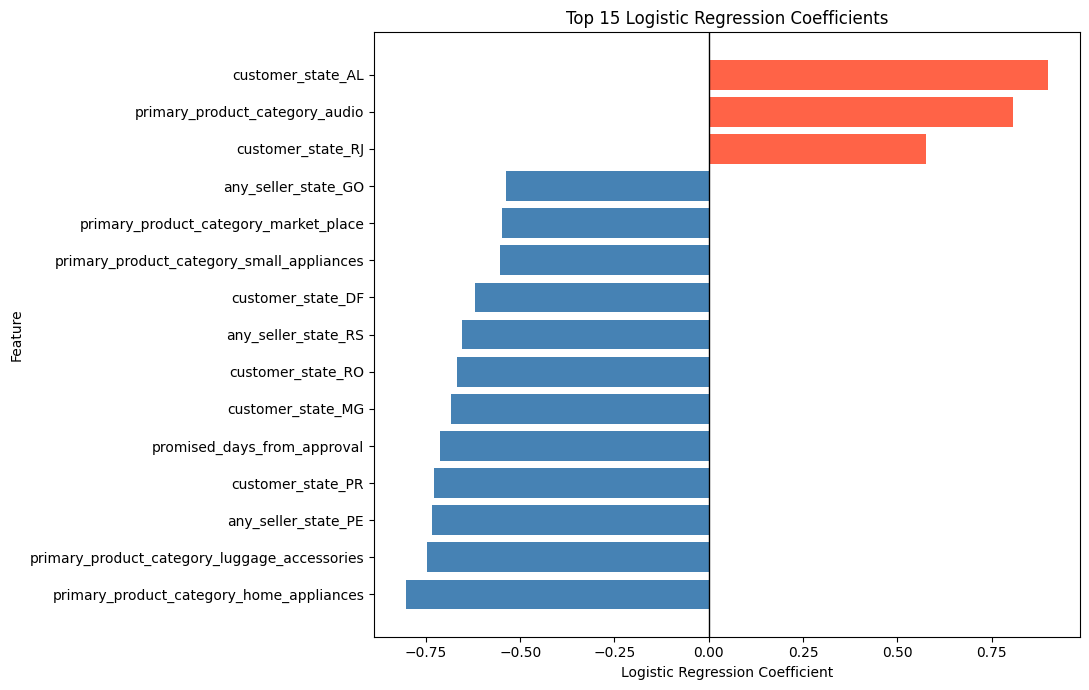

In [57]:
import matplotlib.pyplot as plt
import numpy as np

top15 = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(11, 7))

colors = np.where(
    top15["Coefficient"] > 0,
    "tomato",
    "steelblue"
)

plt.barh(
    top15["Feature"],
    top15["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

### 4.2.3 Permutation Feature Importance

While logistic regression coefficients indicate the direction and magnitude of associations in the fitted model, they do not directly measure each feature's contribution to predictive performance.

To provide a complementary perspective, permutation importance evaluates the decrease in PR-AUC after randomly shuffling one feature while keeping the others unchanged.

We use time-based validation data drawn exclusively from the training period. The model is fitted on earlier observations and evaluated on later observations, avoiding in-sample importance estimates and preserving the held-out test set for final evaluation.

In [58]:
# There are some personal issues with this environment. But the issue was resolved.
import sys
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "src").exists():
    root = root.parent

sys.path.insert(0, str(root))
from sklearn.base import clone
from src.evaluation import cv_splitter

# Use the team's existing time-series cross-validation strategy
cv = cv_splitter()

# Select the last training/validation split
train_idx, val_idx = list(cv.split(X_train_sel, y_train))[-1]

# Create chronological training and validation subsets
X_fit = X_train_sel.iloc[train_idx]
X_val = X_train_sel.iloc[val_idx]

y_fit = y_train.iloc[train_idx]
y_val = y_train.iloc[val_idx]

# Fit a fresh logistic regression pipeline
lr_val_model = clone(candidates["Logistic Regression"])
lr_val_model.fit(X_fit, y_fit)

print("Training observations:", len(X_fit))
print("Validation observations:", len(X_val))
print("Validation late rate:", round(y_val.mean(), 4))

Training observations: 53365
Validation observations: 10673
Validation late rate: 0.1884


In [59]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Baseline performance on validation data
y_score = lr_val_model.predict_proba(X_val)[:, 1]

baseline_ap = average_precision_score(y_val, y_score)

print(f"Validation PR-AUC: {baseline_ap:.4f}")

# Permutation importance
perm_result = permutation_importance(
    lr_val_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organize results
perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

display(perm_df.head(15))

Validation PR-AUC: 0.3601


,Feature,Importance,Std
5,customer_state,0.112183,0.004025
0,promised_days_from_approval,0.051577,0.004804
16,same_state_item_share,0.031514,0.001528
14,mean_distance_km,0.020776,0.001500
17,any_seller_state,0.018117,0.001417
6,item_count,0.009093,0.001206
18,primary_product_category,0.008398,0.002622
9,total_price,0.005303,0.002418
12,max_product_weight_g,0.005201,0.000688
15,max_distance_km,0.003559,0.000682


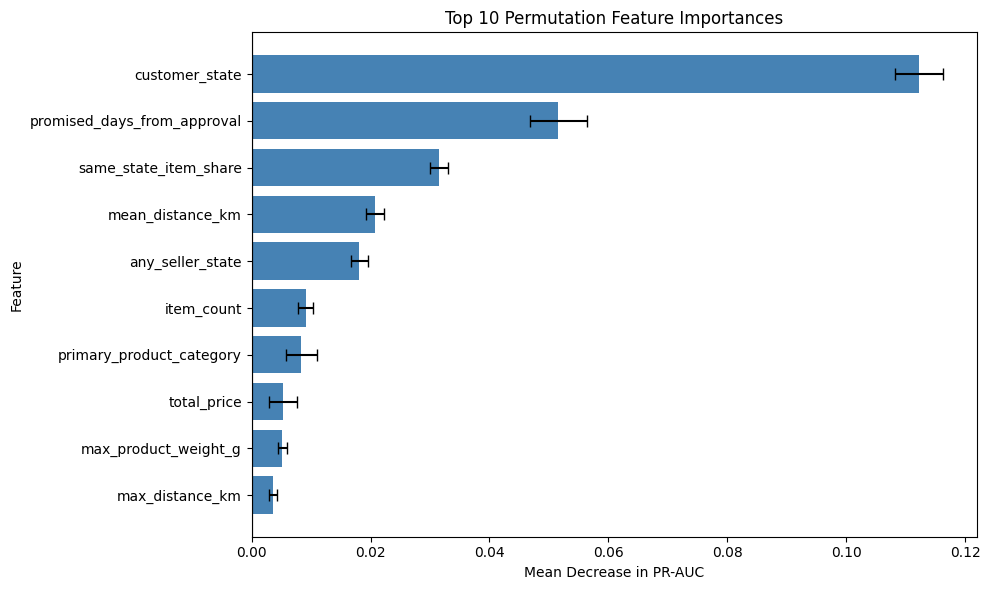

In [60]:
import matplotlib.pyplot as plt

top10 = perm_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Feature"],
    top10["Importance"],
    xerr=top10["Std"],
    color="steelblue",
    capsize=4
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Mean Decrease in PR-AUC")
plt.ylabel("Feature")
plt.title("Top 10 Permutation Feature Importances")

plt.tight_layout()
plt.show()

**Results and Interpretation**

The logistic regression model achieved a validation PR-AUC of 0.3601 on the final time-based validation fold, compared with a late-delivery prevalence of 18.84%.

Permutation importance identifies `customer_state` as the most influential feature, with an average PR-AUC decrease of 0.1122 when shuffled. This is followed by `promised_days_from_approval` (0.0516), `same_state_item_share` (0.0315), and `mean_distance_km` (0.0208).

These findings suggest that geographic information, promised delivery windows, and shipping-related characteristics play important roles in the model's predictions.

Unlike coefficient magnitudes, permutation importance evaluates how much predictive performance depends on each original feature, making it particularly useful when categorical variables are expanded through one-hot encoding.

## 4.3 Error Analysis

### 4.3.1 Confusion Matrix and Top-10% Risk Identification

This section examines the types of prediction errors made by the logistic regression model on time-based validation data.

Following the project's operational objective, we identify the highest-risk 10% of orders based on predicted late-delivery probabilities.

We then construct a confusion matrix to evaluate how many late orders are successfully identified and how many are missed.

All analysis is conducted on the training-period validation fold without accessing the held-out test set.

In [61]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Step 1: Generate predicted late-delivery probabilities
y_prob = lr_val_model.predict_proba(X_val)[:, 1]

# Step 2: Select the highest-risk 10% of orders
n_top = int(np.ceil(len(y_prob) * 0.10))

top_indices = np.argsort(-y_prob, kind="stable")[:n_top]

# Step 3: Create binary predictions
y_pred_top10 = np.zeros(len(y_prob), dtype=int)
y_pred_top10[top_indices] = 1

# Step 4: Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val,
    y_pred_top10,
    labels=[0, 1]
).ravel()

# Step 5: Calculate operational metrics
precision = precision_score(y_val, y_pred_top10, zero_division=0)
recall = recall_score(y_val, y_pred_top10, zero_division=0)

print(f"Validation orders: {len(y_val)}")
print(f"Flagged orders (Top 10%): {n_top}")
print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Negatives: {tn}")
print(f"Precision at Top 10%: {precision:.4f}")
print(f"Recall at Top 10%: {recall:.4f}")

Validation orders: 10673
Flagged orders (Top 10%): 1068
True Positives: 485
False Positives: 583
False Negatives: 1526
True Negatives: 8079
Precision at Top 10%: 0.4541
Recall at Top 10%: 0.2412


**Results and Interpretation**

On the selected time-based validation fold, the logistic regression model flagged the 10% highest-risk orders (1,068 out of 10,673 orders).

Among these flagged orders, 485 were actual late deliveries (true positives), while 583 arrived on time (false positives). The model missed 1,526 late orders (false negatives).

The resulting precision at the top 10% was 45.41%, and recall at the top 10% was 24.12%.

Compared with the validation late-delivery prevalence of 18.84%, the flagged orders had approximately 2.41 times the average late-delivery rate.

These findings suggest that the model provides useful risk prioritization. However, approximately 75.9% of late deliveries remain outside the highest-risk 10%, indicating an important limitation under the assumed operational review capacity.

These results apply to one time-based validation fold, not the held-out test set.

### 4.3.2 False Negative Analysis

False negatives are orders that were actually delivered late but were not included in the top 10% highest-risk predictions.

To investigate why these orders were missed, we compare their characteristics with true positives, which are late orders successfully identified by the model.

The analysis focuses on promised delivery windows, shipping distances, same-state shipping share, and order-level numerical characteristics.

In [62]:
# Build the error analysis dataset
error_df = X_val.copy().reset_index(drop=True)

error_df["actual"] = y_val.to_numpy()
error_df["predicted"] = y_pred_top10
error_df["predicted_risk"] = y_prob

conditions = [
    (error_df["actual"] == 1) & (error_df["predicted"] == 1),
    (error_df["actual"] == 1) & (error_df["predicted"] == 0),
    (error_df["actual"] == 0) & (error_df["predicted"] == 1),
    (error_df["actual"] == 0) & (error_df["predicted"] == 0)
]

error_df["error_type"] = np.select(
    conditions,
    ["TP", "FN", "FP", "TN"],
    default="Unknown"
)

print(error_df["error_type"].value_counts())

error_type
TN    8079
FN    1526
FP     583
TP     485
Name: count, dtype: int64


In [63]:
# Compare average characteristics of FN and TP orders
features = {
    "promised_days_from_approval": "Promised Days",
    "mean_distance_km": "Mean Distance (km)",
    "same_state_item_share": "Same-State Share",
    "item_count": "Item Count",
    "total_price": "Total Price",
    "total_freight": "Total Freight"
}

comparison = (
    error_df[error_df["error_type"].isin(["FN", "TP"])]
    .groupby("error_type")[list(features)]
    .mean()
    .T
    .rename(index=features)
    .rename(columns={"FN": "FN Mean", "TP": "TP Mean"})
    .round(2)
)

comparison["Finding"] = [
    "FN has slightly longer delivery windows",
    "TP orders travel farther",
    "TP orders are more concentrated in cross-state shipping",
    "Minimal difference",
    "TP orders have higher values",
    "TP orders have higher freight costs"
]

display(comparison.reset_index().rename(columns={"index": "Feature"}))

error_type,Feature,FN Mean,TP Mean,Finding
0,Promised Days,22.67,21.87,FN has slightly longer delivery windows
1,Mean Distance (km),730.47,995.23,TP orders travel farther
2,Same-State Share,0.21,0.00,TP orders are more concentrated in cross-state...
3,Item Count,1.11,1.08,Minimal difference
4,Total Price,126.70,177.31,TP orders have higher values
5,Total Freight,23.12,34.73,TP orders have higher freight costs


**Results and Interpretation**

The comparison between true positives  and false negatives reveals several differences in the characteristics of late deliveries identified and missed by the logistic regression model.

Shipping Distance: Successfully identified late orders have a higher average shipping distance (995.23 km) than missed late orders (730.47 km). This suggests that the model may be more effective at recognizing late deliveries associated with longer shipping routes.

Geographic Characteristics: The average same-state item share is approximately 0.00 for TP orders, compared with 0.21 for FN orders. This indicates that missed late deliveries include a greater proportion of within-state shipments, while correctly identified late deliveries are more concentrated among cross-state shipments.

Order Value and Freight: TP orders have higher average order values (177.31 vs. 126.70) and freight costs (34.73 vs. 23.12). The model may be more likely to assign higher risk scores to orders with these characteristics.

Promised Delivery Window: FN orders have slightly longer average promised delivery windows (22.67 days) than TP orders (21.87 days), although this difference is relatively small.

### 4.3.3 False Positive Analysis

False positives are orders that were flagged among the top 10% highest-risk predictions but were actually delivered on time.

To understand these incorrect alerts, we compare false positives (FP) with true negatives (TN). Both groups were delivered on time, but only FP orders were flagged as high-risk.

The objective is to identify characteristics associated with unnecessary risk alerts and assess potential operational inefficiencies.

In [64]:
# Compare FP and TN characteristics
fp_tn = (
    error_df[error_df["error_type"].isin(["FP", "TN"])]
    .groupby("error_type")[list(features)]
    .mean()
    .T
    .rename(index=features)
    .rename(columns={"FP": "FP Mean", "TN": "TN Mean"})
    .round(2)
)

# Display a clean comparison table
fp_tn = fp_tn.reset_index().rename(
    columns={"index": "Feature"}
)

display(fp_tn)

error_type,Feature,FP Mean,TN Mean
0,Promised Days,22.97,21.70
1,Mean Distance (km),1159.05,520.31
2,Same-State Share,0.06,0.42
3,Item Count,1.15,1.16
4,Total Price,231.14,124.31
5,Total Freight,39.22,21.21


**Results and Interpretation**

The comparison between false positives (FP) and true negatives (TN) reveals clear differences in shipping-related characteristics, even though both groups were ultimately delivered on time.

Shipping Distance: FP orders have a substantially higher average shipping distance (1,159.05 km) than TN orders (520.31 km). This suggests that the model tends to assign higher risk scores to long-distance shipments, including those that arrive on time.

Geographic Characteristics: The average same-state item share is much lower for FP orders (0.06) than for TN orders (0.42), indicating a greater concentration of cross-state shipments among false positives.

Order Value and Freight: FP orders have higher average order values (231.14 vs. 124.31) and freight costs (39.22 vs. 21.21). These characteristics may be associated with the model's higher risk predictions.

Promised Delivery Window: FP orders have slightly longer promised delivery windows (22.97 days) than TN orders (21.70 days), while item counts are nearly identical.

### 4.3.4 Cross-Model Error Comparison

We compare three shortlisted models—Logistic Regression, Random Forest, and Gradient Boosting (HistGB)—using the same chronological training and validation split.

Each model identifies the highest-risk 10% of orders. We compare PR-AUC, Precision@10%, and Recall@10%, followed by an analysis of overlapping and model-specific prediction errors.

The held-out test set is not used.

In [65]:
# Fit HistGB on the same training fold
hgb_val_model = clone(candidates["Gradient Boosting (HistGB)"])
hgb_val_model.fit(X_fit, y_fit)

# Predict validation risk
hgb_prob = hgb_val_model.predict_proba(X_val)[:, 1]

# Select the highest-risk 10%
hgb_top_idx = np.argsort(-hgb_prob, kind="stable")[:n_top]

hgb_pred_top10 = np.zeros(len(hgb_prob), dtype=int)
hgb_pred_top10[hgb_top_idx] = 1

print("HistGB fitted and predictions generated.")

HistGB fitted and predictions generated.


In [66]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_score, recall_score

# Train Random Forest on the same training fold
rf_val_model = clone(candidates["Random Forest"])
rf_val_model.fit(X_fit, y_fit)

# Predict late-delivery risk
rf_prob = rf_val_model.predict_proba(X_val)[:, 1]

# Flag the highest-risk 10% of orders
rf_top_idx = np.argsort(-rf_prob, kind="stable")[:n_top]

rf_pred_top10 = np.zeros(len(rf_prob), dtype=int)
rf_pred_top10[rf_top_idx] = 1

# Compare model performance
comparison_models = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting (HistGB)"
    ],
    "PR-AUC": [
        average_precision_score(y_val, y_prob),
        average_precision_score(y_val, rf_prob),
        average_precision_score(y_val, hgb_prob)
    ],
    "Precision@10%": [
        precision_score(y_val, y_pred_top10),
        precision_score(y_val, rf_pred_top10),
        precision_score(y_val, hgb_pred_top10)
    ],
    "Recall@10%": [
        recall_score(y_val, y_pred_top10),
        recall_score(y_val, rf_pred_top10),
        recall_score(y_val, hgb_pred_top10)
    ]
})

display(comparison_models.round(4))

,Model,PR-AUC,Precision@10%,Recall@10%
0,Logistic Regression,0.3601,0.4541,0.2412
1,Random Forest,0.3382,0.4335,0.2302
2,Gradient Boosting (HistGB),0.3351,0.4223,0.2243


In [67]:
actual_late = y_val.to_numpy() == 1

lr_detected = actual_late & (y_pred_top10 == 1)
rf_detected = actual_late & (rf_pred_top10 == 1)
hgb_detected = actual_late & (hgb_pred_top10 == 1)

overlap_summary = pd.DataFrame({
    "Category": [
        "Missed by all three models",
        "Detected by all three models",
        "Detected by at least one model",
        "Detected only by Logistic Regression",
        "Detected only by Random Forest",
        "Detected only by HistGB"
    ],
    "Orders": [
        np.sum(actual_late & ~lr_detected & ~rf_detected & ~hgb_detected),
        np.sum(lr_detected & rf_detected & hgb_detected),
        np.sum(lr_detected | rf_detected | hgb_detected),
        np.sum(lr_detected & ~rf_detected & ~hgb_detected),
        np.sum(rf_detected & ~lr_detected & ~hgb_detected),
        np.sum(hgb_detected & ~lr_detected & ~rf_detected)
    ]
})

display(overlap_summary)

,Category,Orders
0,Missed by all three models,1261
1,Detected by all three models,219
2,Detected by at least one model,750
3,Detected only by Logistic Regression,140
4,Detected only by Random Forest,75
5,Detected only by HistGB,105


**Results and Interpretation**

On the selected time-based validation fold, Logistic Regression achieved the highest PR-AUC (0.3601), Precision@10% (0.4541), and Recall@10% (0.2412), followed by Random Forest and HistGB.

The error overlap analysis shows that all three models missed 1,261 of the 2,011 actual late deliveries (62.7%), suggesting substantial shared prediction limitations.

However, the models also demonstrate complementary behavior. Logistic Regression uniquely detected 140 late orders, Random Forest uniquely detected 75, and HistGB uniquely detected 105. In total, at least one of the three models identified 750 late orders (37.3%).

Although Logistic Regression performed best individually on this validation fold, Random Forest and HistGB identified some late deliveries that Logistic Regression missed. This suggests potential benefits from combining different model families.

However, the combined coverage of 37.3% does not represent the performance of an operational ensemble under the top-10% review constraint. Any ensemble would need to be evaluated using a single risk ranking and the same review capacity.